# 07 — Random Forest: train, tune and interpret

Run after Notebooks 01–05, using **Restart Kernel and Run All** in the project kernel. This is one of the four classifier notebooks (06–09). Each loads the same prepared folds; no earlier model must be trained first. Missing folds are prepared safely through `prepare.py`, without any combined model-training notebook.

The declared 16-trial search, references, metrics and report notes below are retained from the completed Optuna study. Every trial uses all three expanding 2025 folds. Mean fold average precision (AP) selects the configuration; the earliest trial breaks ties. The selected candidate is fitted through December 2025; January–March 2026 validation selects its F1 cutoff. These periods have already been inspected, so this remains exploratory/reproduction work. No test rows or registered November outcomes are read.

Each execution saves a new `07_random_forest/<timestamp>/` folder inside the active data run. Nothing replaces an existing dashboard model. Run **10_model_comparison.ipynb** after all four model notebooks to compare matching results without refitting. Section 1 explains the technique, sections 4–6 show results, and section 7 supports report writing.


## 1. Settings and technique

Random Forest averages predictions from many decision trees trained on bootstrap samples. Random feature sampling reduces similarity between trees. It can learn nonlinear relationships and interactions. Numerical features are median-imputed with missing indicators; categorical features are one-hot encoded. Trees do not need numerical scaling. Every fit learns preprocessing from its training fold only.

| Hyperparameter | Search options | Purpose |
|---|---|---|
| `max_depth` | 8, 16, 24 | Limit tree complexity. |
| `min_samples_leaf` | 5, 10, 20, 40 | Require support for each leaf. |
| `max_features` | `"sqrt"`, 0.5 | Use square-root or half of the transformed features at each split. |
| `class_weight` | `None`, `"balanced_subsample"` | Equal sample weights or class weights recalculated within each training bootstrap sample. |

The first two trials reproduce Notebook 06's depth-8/depth-16 settings: 150 trees, minimum leaf size 10, square-root feature sampling and balanced subsampling. The next two use those same settings without weighting. Scores remain uncalibrated. Keep this search fixed instead of repeatedly enlarging it after viewing results.

In [1]:
import sys
from pathlib import Path
REPOSITORY_ROOT = Path.cwd()
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    raise FileNotFoundError("Open the FYP project folder before running this notebook.")
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

import hashlib
import json
from datetime import datetime, timezone
from importlib import metadata, reload
from time import perf_counter
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import optuna
except ModuleNotFoundError:
    raise ModuleNotFoundError("Install Optuna in this kernel: %pip install 'optuna>=4,<5', then restart and Run All.") from None
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import pricecatcher_config as cfg
cfg = reload(cfg)

SEED = 42
N_TRIALS = 16
TREES = 150
N_JOBS = 2
SEARCH_SPACE = {
    "max_depth": [8, 16, 24],
    "min_samples_leaf": [5, 10, 20, 40],
    "max_features": ["sqrt", 0.5],
    "class_weight": [None, "balanced_subsample"],
}
REFERENCE_SETTINGS = [
    ("Reference depth=8", {"max_depth": 8, "min_samples_leaf": 10,
                           "max_features": "sqrt", "class_weight": "balanced_subsample"}),
    ("Reference depth=16", {"max_depth": 16, "min_samples_leaf": 10,
                            "max_features": "sqrt", "class_weight": "balanced_subsample"}),
    ("Unweighted depth=8", {"max_depth": 8, "min_samples_leaf": 10,
                            "max_features": "sqrt", "class_weight": None}),
    ("Unweighted depth=16", {"max_depth": 16, "min_samples_leaf": 10,
                             "max_features": "sqrt", "class_weight": None}),
]
FOLDS = ["fold_1", "fold_2", "fold_3"]
print("Python:", sys.executable)
print("Prepared run:", cfg.PROJECT_ROOT)
print("Trials:", N_TRIALS, "| Folds:", len(FOLDS), "| Trees:", TREES, "| Fixed target: 10%")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /usr/local/bin/python3.12
Prepared run: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240
Trials: 16 | Folds: 3 | Trees: 150 | Fixed target: 10%


## 2. Continue the preparation from Notebook 05

The holdout train/validation inputs must already exist. They are never regenerated here. Existing complete expanding folds are reused. If a fold is absent, the existing `prepare.py` runs only preparation notebooks for that fold, using the verified local source; it does not train the old comparison models.

Partial fold inputs and missing inputs belonging to saved experiments stop execution rather than being overwritten. Restore a matching completed snapshot or start a deliberate new preparation from 01 if needed. The helper still applies item eligibility and cleaning rules using each fold's training period. This avoids deriving early-fold filters from all of 2025.

In [2]:
def file_hash(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

folders = {name: cfg.PROJECT_ROOT / "experiments" / name / "05_modelling"
           for name in FOLDS + ["holdout"]}
input_paths = [folder / filename for folder in folders.values()
               for filename in ["experiment_settings.json", "train.parquet", "validation.parquet"]]
# A manual Run All in 01–05 normally prepares holdout only.
required_names = ["experiment_settings.json", "train.parquet", "validation.parquet"]
holdout_missing = [str(folders["holdout"] / name) for name in required_names
                   if not (folders["holdout"] / name).is_file()]
if holdout_missing:
    raise FileNotFoundError("Complete Notebook 05 first. Missing: " + ", ".join(holdout_missing))
holdout_hashes = {name: file_hash(folders["holdout"] / name) for name in required_names}
missing_folds = [name for name in FOLDS
                 if not all((folders[name] / filename).is_file() for filename in required_names)]
if missing_folds:
    partial_folds = [name for name in missing_folds
                     if folders[name].exists() and any(folders[name].iterdir())]
    saved_models = any((folder / "best_model.joblib").exists() for folder in cfg.MODEL_DIRS)
    saved_studies = (any(cfg.PROJECT_ROOT.glob("*_optuna/*/study_manifest.json"))
                     or any(cfg.PROJECT_ROOT.glob("0[6-9]_*/*/study_manifest.json")))
    if partial_folds or saved_models or saved_studies:
        raise FileNotFoundError(
            f"Incomplete folds: {missing_folds}. Restore their matching prepared inputs; "
            "partial inputs or saved experiments are present. To reproduce from source, start a separate run with 01–05.")
    if not (REPOSITORY_ROOT / "prepare.py").is_file():
        raise FileNotFoundError("Keep prepare.py beside this notebook; it prepares missing chronological folds.")
    cfg.verify_source_snapshot()
    import os
    import subprocess
    for name in missing_folds:
        print("Preparing chronological inputs (no model training):", name, flush=True)
        subprocess.run([sys.executable, str(REPOSITORY_ROOT / "prepare.py"), "--experiment", name],
                       cwd=REPOSITORY_ROOT,
                       env={**os.environ, "PRICECATCHER_DATA_DIR": str(cfg.PROJECT_ROOT)}, check=True)
if any(file_hash(folders["holdout"] / name) != digest for name, digest in holdout_hashes.items()):
    raise ValueError("Holdout preparation changed during fold preparation. Stop and restore the matching snapshot.")
missing = [str(path) for path in input_paths if not path.is_file()]
if missing:
    raise FileNotFoundError("Preparation did not produce the required files: " + ", ".join(missing))
input_hashes = {str(path.relative_to(cfg.PROJECT_ROOT)): file_hash(path) for path in input_paths}
settings_by_fold = {name: json.loads((folder / "experiment_settings.json").read_text())
                    for name, folder in folders.items()}
settings = settings_by_fold["holdout"]
FEATURES = settings["feature_columns"]
NUMERIC = settings["numeric_features"]
CATEGORICAL = settings["categorical_features"]
if len(FEATURES) != len(set(FEATURES)) or sorted(NUMERIC + CATEGORICAL) != sorted(FEATURES):
    raise ValueError("Numeric and categorical features must partition the feature list.")
if any(c.startswith("next_") or c in ["surge_label", "split"] for c in FEATURES):
    raise ValueError("Future outcomes must not enter the model features.")
if settings["surge_threshold_pct"] != 10:
    raise ValueError("This study requires the existing fixed 10% target.")
variable = {"experiment", "train_end", "validation_end", "test_end", "evaluation_end",
            "apply_documented_exclusions", "source_manifest_sha256", "source_snapshot_sha256"}
policy = {k: v for k, v in settings["preparation"].items() if k not in variable}
source_key = ("source_snapshot_sha256" if settings["preparation"].get("source_snapshot_sha256")
              else "source_manifest_sha256")
source_id = settings["preparation"].get(source_key)
if not source_id:
    raise ValueError("Source identity is missing; restore matching preparation metadata.")

frames = {}
for name, folder in folders.items():
    s = settings_by_fold[name]
    if tuple(s[k] for k in ["train_end", "validation_end", "test_end"]) != tuple(cfg.EXPERIMENTS[name]):
        raise ValueError(f"{name}: date settings differ from the configured chronological experiment.")
    for key in ["feature_columns", "numeric_features", "categorical_features", "target_status", "surge_threshold_pct"]:
        if s[key] != settings[key]:
            raise ValueError(f"{name}: incompatible {key}.")
    if ({k: v for k, v in s["preparation"].items() if k not in variable} != policy
            or s["preparation"].get(source_key) != source_id
            or s["preparation"].get("experiment") != name):
        raise ValueError(f"{name}: shared source/policies differ. Restore consistent prepared inputs.")
    if name in FOLDS and s["preparation"].get("apply_documented_exclusions"):
        raise ValueError("Early folds must retain retrospective exceptions whose review dates are unknown.")
    frames[name] = {}
    for split in ["train", "validation"]:
        frame = pd.read_parquet(folder / f"{split}.parquet")
        required = FEATURES + ["surge_label", "week_start", "next_week_end", "project_group"]
        if frame.empty or set(required) - set(frame.columns):
            raise ValueError(f"{name}/{split}: empty or incomplete input.")
        if frame.surge_label.isna().any() or not frame.surge_label.isin([0, 1]).all() or frame.surge_label.nunique() != 2:
            raise ValueError(f"{name}/{split}: overall evaluation requires both observed classes.")
        for col in ["week_start", "next_week_end"]:
            frame[col] = pd.to_datetime(frame[col])
        if (frame[["week_start", "next_week_end"]].isna().any().any()
                or not frame.week_start.dt.dayofweek.eq(0).all()
                or not frame.next_week_end.eq(frame.week_start + pd.Timedelta(days=13)).all()):
            raise ValueError(f"{name}/{split}: invalid calendar-week horizons.")
        upper = pd.Timestamp(s["train_end" if split == "train" else "validation_end"])
        if not frame.next_week_end.le(upper).all():
            raise ValueError(f"{name}/{split}: outcome crosses its time boundary.")
        if split == "validation" and not (frame.week_start + pd.Timedelta(days=6)).gt(pd.Timestamp(s["train_end"])).all():
            raise ValueError(f"{name}: validation overlaps training.")
        if frame.duplicated(["item_code", "state", "district", "premise_type", "week_start"]).any():
            raise ValueError(f"{name}/{split}: duplicate local series/week.")
        if np.isinf(frame[NUMERIC].to_numpy(dtype=float)).any():
            raise ValueError(f"{name}/{split}: infinite numeric input.")
        frames[name][split] = frame

display(pd.DataFrame([{"experiment": name, "train_end": s["train_end"],
                      "validation_end": s["validation_end"],
                      "training_rows": len(frames[name]["train"]),
                      "validation_rows": len(frames[name]["validation"])}
                     for name, s in settings_by_fold.items()]))

,experiment,train_end,validation_end,training_rows,validation_rows
0,fold_1,2025-05-31,2025-07-31,66384,31971
1,fold_2,2025-07-31,2025-09-30,101515,31753
2,fold_3,2025-09-30,2025-12-31,138296,54666
3,holdout,2025-12-31,2026-03-31,195664,43594


## 3. Pipeline, metrics and baselines

Use one fresh pipeline for each trial/fold. Classification comparisons use the common 0.5 reference cutoff; AP selects parameters independently of that cutoff. Weighting can shift scores, so F1 at 0.5 and AP answer different questions.

The current-change baseline ranks by the observed weekly percentage change and alerts at 10%, following the saved label tolerance. The no-surge baseline always predicts zero. Positive-case metrics remain missing for groups without surges; precision is recorded as zero when there are no alerts.

In [3]:
def model_inputs(frame):
    X = frame[FEATURES].copy()
    for column in CATEGORICAL:
        X[column] = X[column].astype("string").fillna("__missing__").astype(str)
    return X


def build_pipeline(parameters):
    numeric = SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    preprocessing = ColumnTransformer([
        ("numeric", numeric, NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL),
    ], sparse_threshold=1.0)
    model = RandomForestClassifier(n_estimators=TREES, bootstrap=True, criterion="gini",
                                   random_state=SEED, n_jobs=N_JOBS, **parameters)
    return Pipeline([("preprocess", preprocessing), ("model", model)])


def fit_and_score(parameters, training, evaluation):
    pipeline = build_pipeline(parameters)
    pipeline.fit(model_inputs(training), training.surge_label.astype(int))
    scores = pipeline.predict_proba(model_inputs(evaluation))[:, 1]
    if not np.isfinite(scores).all() or not ((scores >= 0) & (scores <= 1)).all():
        raise ValueError("Model scores must be finite and in [0, 1].")
    return pipeline, scores


def evaluate(y, scores, predictions):
    y, scores, predictions = np.asarray(y, dtype=int), np.asarray(scores), np.asarray(predictions, dtype=int)
    if not len(y) or len(y) != len(scores) or len(y) != len(predictions) or not np.isfinite(scores).all():
        raise ValueError("Metrics require aligned nonempty arrays and finite scores.")
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()
    return {"rows": len(y), "positives": int(y.sum()), "alerts": int(predictions.sum()),
            "average_precision": float(average_precision_score(y, scores)) if len(np.unique(y)) == 2 else np.nan,
            "precision": float(precision_score(y, predictions, zero_division=0)),
            "recall": float(recall_score(y, predictions, zero_division=0)) if y.sum() else np.nan,
            "f1": float(f1_score(y, predictions, zero_division=0)) if y.sum() else np.nan,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


def baselines(frame):
    change = frame.weekly_price_change_pct.to_numpy(dtype=float)
    if not np.isfinite(change).all():
        raise ValueError("Current-change baseline requires supported previous-week prices.")
    tolerance = settings["preparation"].get("label_tolerance_pct", 0.0)
    alerts = (change >= 10) | np.isclose(change, 10, atol=tolerance, rtol=0)
    return {"Always no surge": (np.zeros(len(frame)), np.zeros(len(frame), dtype=int)),
            "Current-change rule": (change, alerts.astype(int))}

## 4. Optuna search on the 2025 folds

A seeded TPE sampler proposes the four hyperparameters together. All trials use every fold and the same eligible rows. The first four queued references ensure both weighting choices are tested. In result tables, `none` means Python `None`, preventing unweighted rows from disappearing in grouped summaries. Saved model parameters retain the actual Python/JSON values.

Report the search budget and fit time: 16 trials mean 48 forest fits before the separate validation fits. Running the full data may take longer than Logistic Regression. A higher maximum search score is not independent evidence of improvement because the search explicitly selects that score.

Exact repeated configurations reuse the same run’s three fold metrics. The saved `reused_from_trial` column identifies the first evaluation; reused rows have zero additional fitting time. There are still 16 recorded Optuna trials, with the same sampler/objective and earliest-trial tie rule. Existing saved outputs below predate this runtime optimisation; future runs print the distinct-configuration count.

In [4]:
trial_fold_rows = []
trial_cache = {}  # Same prepared folds, seed and exact parameters within this run only.

def objective(trial):
    parameters = {name: trial.suggest_categorical(name, choices)
                  for name, choices in SEARCH_SPACE.items()}
    cache_key = json.dumps(trial.params, sort_keys=True)
    if cache_key in trial_cache:
        original_rows = trial_cache[cache_key]
        trial_fold_rows.extend({**row, "trial": trial.number, "reused_from_trial": row["trial"],
                                "fit_and_score_seconds": 0.0} for row in original_rows)
        return float(np.mean([row["average_precision"] for row in original_rows]))
    first_row = len(trial_fold_rows)
    aps = []
    for name in FOLDS:
        training, evaluation = frames[name]["train"], frames[name]["validation"]
        started = perf_counter()
        pipeline, scores = fit_and_score(parameters, training, evaluation)
        metrics = evaluate(evaluation.surge_label, scores, scores >= 0.5)
        trial_fold_rows.append({"trial": trial.number, **parameters,
                               "class_weight": parameters["class_weight"] or "none", "fold": name,
                               "fit_and_score_seconds": perf_counter() - started, **metrics})
        aps.append(metrics["average_precision"])
        del pipeline
    trial_cache[cache_key] = [row.copy() for row in trial_fold_rows[first_row:]]
    return float(np.mean(aps))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.NopPruner())
for label, parameters in REFERENCE_SETTINGS:
    study.enqueue_trial(parameters)
study.optimize(objective, n_trials=N_TRIALS, n_jobs=1)
print(f"Completed {N_TRIALS} trials: {len(trial_cache)} distinct configurations; repeated settings reused without refitting.")
best_trial = max(study.trials, key=lambda trial: (trial.value, -trial.number))
BEST_PARAMETERS = best_trial.params
trial_folds = pd.DataFrame(trial_fold_rows)
trial_summary = trial_folds.groupby("trial", as_index=False).agg(
    max_depth=("max_depth", "first"), min_samples_leaf=("min_samples_leaf", "first"),
    max_features=("max_features", "first"), class_weight=("class_weight", "first"),
    mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
    mean_f1_at_05=("f1", "mean"), mean_precision_at_05=("precision", "mean"),
    mean_recall_at_05=("recall", "mean"), total_fit_and_score_seconds=("fit_and_score_seconds", "sum"))
display(trial_summary.sort_values(["mean_ap", "trial"], ascending=[False, True]))
print("Selected parameters:", BEST_PARAMETERS, "| Mean fold AP:", best_trial.value)

comparison_rows = []
reference_trials = [(label, number) for number, (label, _) in enumerate(REFERENCE_SETTINGS)]
for label, trial_number in reference_trials + [("Optuna selected", best_trial.number)]:
    for row in trial_fold_rows:
        if row["trial"] == trial_number:
            comparison_rows.append({"method": label, **row})
for name in FOLDS:
    evaluation = frames[name]["validation"]
    for label, (scores, predictions) in baselines(evaluation).items():
        comparison_rows.append({"method": label, "fold": name,
                                **evaluate(evaluation.surge_label, scores, predictions)})
fold_comparison = pd.DataFrame(comparison_rows)
fold_summary = fold_comparison.groupby("method").agg(
    mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
    mean_precision=("precision", "mean"), mean_recall=("recall", "mean"), mean_f1=("f1", "mean"))
display(fold_summary)

[I 2026-10-27 17:48:49,281] A new study created in memory with name: no-name-f92fe2ef-bd57-4a72-bf65-c96d6ebe3a6d
[I 2026-10-27 17:49:01,060] Trial 0 finished with value: 0.32092324422625 and parameters: {'max_depth': 8, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}. Best is trial 0 with value: 0.32092324422625.
[I 2026-10-27 17:49:28,305] Trial 1 finished with value: 0.34462140427264093 and parameters: {'max_depth': 16, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}. Best is trial 1 with value: 0.34462140427264093.
[I 2026-10-27 17:49:38,164] Trial 2 finished with value: 0.32484619446469787 and parameters: {'max_depth': 8, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_weight': None}. Best is trial 1 with value: 0.34462140427264093.
[I 2026-10-27 17:50:05,240] Trial 3 finished with value: 0.34157537020347606 and parameters: {'max_depth': 16, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_wei

,trial,max_depth,min_samples_leaf,max_features,class_weight,mean_ap,std_ap,mean_f1_at_05,mean_precision_at_05,mean_recall_at_05,total_fit_and_score_seconds
8,8,16,40,0.5,none,0.348595,0.069108,0.107846,0.613452,0.060877,197.058881
15,15,16,40,0.5,none,0.348595,0.069108,0.107846,0.613452,0.060877,128.890383
10,10,24,40,0.5,none,0.348028,0.068525,0.106905,0.613951,0.060094,195.707718
11,11,24,40,0.5,none,0.348028,0.068525,0.106905,0.613951,0.060094,223.713064
12,12,24,40,0.5,none,0.348028,0.068525,0.106905,0.613951,0.060094,176.268240
13,13,24,40,0.5,none,0.348028,0.068525,0.106905,0.613951,0.060094,135.139169
14,14,24,40,0.5,none,0.348028,0.068525,0.106905,0.613951,0.060094,126.051057
7,7,16,20,0.5,balanced_subsample,0.347962,0.061230,0.392315,0.319257,0.518850,223.230284
1,1,16,10,sqrt,balanced_subsample,0.344621,0.047516,0.384665,0.268266,0.684012,27.240087
4,4,16,5,sqrt,none,0.342303,0.055347,0.025183,0.687780,0.013258,31.882300


Selected parameters: {'max_depth': 16, 'min_samples_leaf': 40, 'max_features': 0.5, 'class_weight': None} | Mean fold AP: 0.34859515341816655


,mean_ap,std_ap,mean_precision,mean_recall,mean_f1
method,,,,,
Always no surge,0.106114,0.010602,0.000000,0.000000,0.000000
Current-change rule,0.120974,0.026823,0.189686,0.193252,0.191330
Optuna selected,0.348595,0.069108,0.613452,0.060877,0.107846
Reference depth=16,0.344621,0.047516,0.268266,0.684012,0.384665
Reference depth=8,0.320923,0.031037,0.208770,0.853461,0.335407
Unweighted depth=16,0.341575,0.054879,0.645460,0.009983,0.019102
Unweighted depth=8,0.324846,0.038295,0.162602,0.002216,0.004372


## 5. Separate exploratory validation: January–March 2026

Fit each Random Forest setting on the same training rows through December 2025. Compare AP and classification metrics at the common 0.5 reference cutoff. This validation period has already been inspected in earlier work; do not treat it as a fresh test.

Also choose an F1-maximising cutoff for the Optuna candidate on this validation period, breaking ties with the highest cutoff. Its resulting classification metrics are **apparent cutoff-selection performance**, not an independent estimate. Do not select the best model again using this table. The saved candidate is not promoted to the dashboard.

In [5]:
training = frames["holdout"]["train"]
validation = frames["holdout"]["validation"]
validation_rows = []
validation_scores = {}
for label, parameters in REFERENCE_SETTINGS + [("Optuna selected", BEST_PARAMETERS)]:
    pipeline, scores = fit_and_score(parameters, training, validation)
    validation_scores[label] = scores
    validation_rows.append({"method": label, **parameters,
                            "class_weight": parameters["class_weight"] or "none", "cutoff": 0.5,
                            **evaluate(validation.surge_label, scores, scores >= 0.5)})
    if label == "Optuna selected":
        selected_pipeline = pipeline
for label, (scores, predictions) in baselines(validation).items():
    validation_rows.append({"method": label, **evaluate(validation.surge_label, scores, predictions)})
selected_scores = validation_scores["Optuna selected"]
precision, recall, cutoffs = precision_recall_curve(validation.surge_label, selected_scores)
f1 = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
               out=np.zeros(len(cutoffs)), where=(precision[:-1] + recall[:-1]) > 0)
selected_cutoff = float(cutoffs[np.flatnonzero(np.isclose(f1, f1.max(), atol=1e-12, rtol=0))[-1]])
validation_rows.append({"method": "Optuna selected: apparent cutoff-selection performance",
                        **BEST_PARAMETERS, "class_weight": BEST_PARAMETERS["class_weight"] or "none",
                        "cutoff": selected_cutoff,
                        **evaluate(validation.surge_label, selected_scores, selected_scores >= selected_cutoff)})
validation_comparison = pd.DataFrame(validation_rows)
display(validation_comparison)
group_rows = []
for group, positions in validation.groupby("project_group", sort=True).indices.items():
    group_rows.append({"project_group": group,
        **evaluate(validation.iloc[positions].surge_label, selected_scores[positions],
                    selected_scores[positions] >= selected_cutoff)})
group_comparison = pd.DataFrame(group_rows)
display(group_comparison)
print("These group metrics also reuse the cutoff-selection period, not an untouched test.")

,method,max_depth,min_samples_leaf,max_features,class_weight,cutoff,rows,positives,alerts,average_precision,precision,recall,f1,tp,fp,fn,tn
0,Reference depth=8,8.0,10.0,sqrt,balanced_subsample,0.500000,43594,3912,22794,0.297260,0.165000,0.961401,0.281660,3761,19033,151,20649
1,Reference depth=16,16.0,10.0,sqrt,balanced_subsample,0.500000,43594,3912,17656,0.301785,0.196874,0.888548,0.322329,3476,14180,436,25502
2,Unweighted depth=8,8.0,10.0,sqrt,none,0.500000,43594,3912,2,0.300662,1.000000,0.000511,0.001022,2,0,3910,39682
3,Unweighted depth=16,16.0,10.0,sqrt,none,0.500000,43594,3912,273,0.301947,0.611722,0.042689,0.079809,167,106,3745,39576
4,Optuna selected,16.0,40.0,0.5,none,0.500000,43594,3912,1448,0.250297,0.299033,0.110685,0.161567,433,1015,3479,38667
5,Always no surge,NaN,NaN,NaN,NaN,NaN,43594,3912,0,0.089737,0.000000,0.000000,0.000000,0,0,3912,39682
6,Current-change rule,NaN,NaN,NaN,NaN,NaN,43594,3912,4417,0.101561,0.175685,0.198364,0.186337,776,3641,3136,36041
7,Optuna selected: apparent cutoff-selection per...,16.0,40.0,0.5,none,0.195624,43594,3912,10555,0.250297,0.237423,0.640593,0.346444,2506,8049,1406,31633


,project_group,rows,positives,alerts,average_precision,precision,recall,f1,tp,fp,fn,tn
0,Chicken,4884,25,110,0.104827,0.090909,0.400000,0.148148,10,100,15,4759
1,Cooking Oil,2178,1,1,0.000927,0.000000,0.000000,0.000000,0,1,1,2176
2,Eggs,8892,53,80,0.128809,0.237500,0.358491,0.285714,19,61,34,8778
3,Flour,1110,15,20,0.251132,0.300000,0.400000,0.342857,6,14,9,1081
4,Rice,384,2,1,0.531250,1.000000,0.500000,0.666667,1,0,1,382
5,Sugar,1837,0,1,NaN,0.000000,NaN,NaN,0,1,0,1836
6,Vegetables,24309,3816,10342,0.253663,0.238832,0.647275,0.348919,2470,7872,1346,12621


These group metrics also reuse the cutoff-selection period, not an untouched test.


## 6. Plots and saved evidence

The plots show search behaviour and validation ranking. The horizontal prevalence reference represents constant-score AP. No plot establishes future reliability. Each new execution saves a separate study; interrupted executions do not publish a completed manifest.

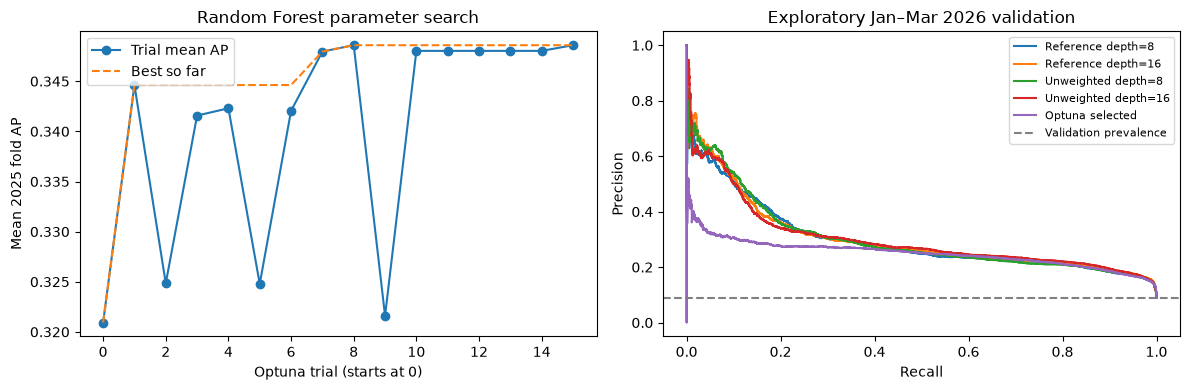

Saved separate research outputs: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/07_random_forest/20261027_104154_770243
Original models, dashboard and active-run selection were not replaced.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ordered = trial_summary.sort_values("trial")
axes[0].plot(ordered.trial, ordered.mean_ap, "o-", label="Trial mean AP")
axes[0].plot(ordered.trial, ordered.mean_ap.cummax(), "--", label="Best so far")
axes[0].set(xlabel="Optuna trial (starts at 0)", ylabel="Mean 2025 fold AP", title="Random Forest parameter search")
axes[0].legend()
for label, scores in validation_scores.items():
    p, r, _ = precision_recall_curve(validation.surge_label, scores)
    axes[1].plot(r, p, label=label)
axes[1].axhline(validation.surge_label.mean(), color="grey", linestyle="--", label="Validation prevalence")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Exploratory Jan–Mar 2026 validation")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

# Recheck exact inputs before publishing this separate result folder.
if any(file_hash(cfg.PROJECT_ROOT / name) != digest for name, digest in input_hashes.items()):
    raise ValueError("Prepared inputs changed during tuning. No completed result is published.")
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
OUTPUT_DIR = cfg.PROJECT_ROOT / "07_random_forest" / stamp
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
for filename, table in {
    "trial_fold_metrics.csv": trial_folds, "trial_summary.csv": trial_summary,
    "fold_comparison.csv": fold_comparison, "fold_summary.csv": fold_summary.reset_index(),
    "validation_comparison.csv": validation_comparison, "validation_group_metrics.csv": group_comparison,
}.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)
study.trials_dataframe().to_csv(OUTPUT_DIR / "optuna_trials.csv", index=False)
fig.savefig(OUTPUT_DIR / "tuning_and_validation.png", dpi=160, bbox_inches="tight")
predictions = validation[["item_code", "state", "district", "premise_type", "project_group",
                          "week_start", "next_week_end", "surge_label"]].copy()
predictions["model_score"] = selected_scores
predictions["alert_at_05"] = selected_scores >= 0.5
predictions["alert_at_selected_cutoff"] = selected_scores >= selected_cutoff
predictions.to_parquet(OUTPUT_DIR / "validation_predictions.parquet", index=False)
joblib.dump(selected_pipeline, OUTPUT_DIR / "random_forest.joblib")
selection = {"family": "Random Forest", "parameters": BEST_PARAMETERS,
             "fixed_parameters": {"n_estimators": TREES, "bootstrap": True, "criterion": "gini"},
             "seed": SEED, "n_jobs": N_JOBS, "trials": N_TRIALS,
             "search": SEARCH_SPACE,
             "reference_settings": [{"method": label, "parameters": parameters}
                                    for label, parameters in REFERENCE_SETTINGS],
             "selection_metric": "mean AP over three expanding 2025 folds; earliest trial breaks ties",
             "selected_trial": best_trial.number, "score_cutoff": selected_cutoff,
             "cutoff_rule": "maximum Jan–Mar validation F1; highest cutoff breaks ties",
             "feature_columns": FEATURES, "surge_threshold_pct": 10.0,
             "training_end": settings["train_end"], "validation_end": settings["validation_end"],
             "refit_on_validation": False, "score_interpretation": "uncalibrated model score"}
(OUTPUT_DIR / "selection.json").write_text(json.dumps(selection, indent=2))
manifest = {"status": "completed", "python_version": sys.version.split()[0], "study_status": "supplementary exploratory tuning; test not accessed",
            "input_sha256": input_hashes, "selection": selection,
            "preparation": {name: s["preparation"] for name, s in settings_by_fold.items()},
            "package_versions": {p: metadata.version(p) for p in ["optuna", "pandas", "numpy", "scikit-learn", "joblib"]},
            "notebook_sha256": file_hash(REPOSITORY_ROOT / "07_random_forest.ipynb"),
            "output_sha256": {p.name: file_hash(p) for p in OUTPUT_DIR.iterdir() if p.is_file()}}
(OUTPUT_DIR / "study_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved separate research outputs:", OUTPUT_DIR)
print("Original models, dashboard and active-run selection were not replaced.")

## 7. Implementation and results notes for the report

**Evidence snapshot:** these notes describe the saved local execution reviewed on **27 October 2026**. They are explanatory Markdown, not new calculations. If a later reproduction changes the outputs, update these historical notes before quoting them as current results. Model selection, code and saved outputs were not changed by adding this explanation.

### 7.1 How Random Forest was implemented

Random Forest trains multiple decision trees on bootstrap samples and averages their class scores:

$$s(x)=\frac{1}{B}\sum_{b=1}^{B}s_b(x),\qquad B=150.$$

Each tree can learn nonlinear relationships and interactions. Random feature subsets help reduce similarity between trees. This differs from boosting: the trees are fitted as an ensemble of bootstrap learners rather than sequential corrections to one score.

Depth controls how complex a tree can become, minimum leaf size requires local support, and feature sampling controls the split candidates. `balanced_subsample` recalculates class weights within each training bootstrap sample; `None` gives equal sample weights. Numerical features are imputed and categorical features encoded using training data only. Scaling is unnecessary for these tree splits. Search options are listed in section 1; 150 trees remain fixed.

All 16 trials are sequential proposals from seeded Optuna TPE. Each proposal is fitted independently on the three expanding 2025 folds, including a fresh preprocessor. The objective is mean fold AP, not accuracy or F1. Four queued references include the original two weighted settings and their unweighted counterparts. A trial is an evaluation attempt, not necessarily a unique configuration; the saved search contains repeated proposals. Keep the actual trial history rather than claiming 16 distinct configurations.

### 7.2 Selected configuration

| Parameter | Selected value |
|---|---|
| `max_depth` | 16 |
| `min_samples_leaf` | 40 |
| `max_features` | 0.5 |
| `class_weight` | None (unweighted) |

The selected setting maximised the declared mean-fold AP objective. Its score cutoff was chosen separately on January–March 2026 validation; changing this cutoff does not alter the 10% price-rise definition.

### 7.3 Evidence of predictive performance

| Method | Mean 2025 fold AP | Fold AP standard deviation | Jan–Mar 2026 validation AP |
|---|---:|---:|---:|
| Always no surge | 0.1061 | 0.0106 | 0.0897 |
| Current-change rule | 0.1210 | 0.0268 | 0.1016 |
| Reference depth=8 | 0.3209 | 0.0310 | 0.2973 |
| Reference depth=16 | 0.3446 | 0.0475 | 0.3018 |
| Optuna selected | 0.3486 | 0.0691 | 0.2503 |

The constant no-surge score has AP equal to prevalence when both classes are present; this does not mean it detects surges. Its precision/recall/F1 under the no-alert rule are zero here. AP is sklearn average precision, not trapezoidal PR-AUC. Fold standard deviation describes temporal variation, not a confidence interval or significance test.

**Interpretation:** The selected candidate increased mean fold AP slightly, but later validation AP fell from 0.3018 for the original depth-16 reference to 0.2503. Fold AP variation also increased (standard deviation 0.0475 to 0.0691). The tuning advantage therefore did not transfer consistently to the later period. The tables cannot isolate whether temporal changes, selection overfitting or other factors caused this.

### 7.4 What the alert cutoff changes

Both rows below use the same selected fitted model and the same **43,594 validation rows**, containing **3,912 surges**. AP is unchanged by moving the cutoff.

| Operating point | Cutoff | Precision | Recall | F1 | Alerts | Correct alerts | False alerts | Missed surges |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Common reference | 0.5000 | 29.9% | 11.1% | 0.1616 | 1,448 | 433 | 1,015 | 3,479 |
| Validation-selected | 0.1956 | 23.7% | 64.1% | 0.3464 | 10,555 | 2,506 | 8,049 | 1,406 |

The selected cutoff maximises F1 on this same validation period, with the highest cutoff breaking ties. These are **apparent cutoff-selection metrics**, not independent test estimates. 76.3% of selected-cutoff alerts were false. The score is uncalibrated; the cutoff is not a verified event probability or a percentage price increase.

### 7.5 Food groups and limitations

Vegetables contribute 2,470 of 2,506 correct alerts. Chicken recall is 40.0% (10/25), while cooking oil has only one positive and rice only two. The single correct rice alert does not establish reliable rice detection. Sugar has no observed surges; its positive-case recall and F1 cannot be assessed.

Overall metrics therefore need group support and recall alongside them. SHAP contributions do not establish economic causes, and this experiment does not demonstrate affordability or stakeholder-adoption benefits. The data were prepared using the existing documented source/coverage rules, so unresolved source quality and changing observation composition remain limitations.

### 7.6 How to explain the result in your report

**Implementation chapter:** describe the technique above, training-fitted preprocessing, parameter ranges in section 1, fixed settings, class-weight policy, 16-trial search, chronological folds and AP objective. Cite appropriate methodological references for the algorithm and Optuna; this notebook is implementation evidence, not a substitute for those references.

**Results chapter:** use section 7.3 for reference-versus-tuned ranking, section 7.4 for the alert trade-off, and the displayed group table for support and uneven performance. Explain both gains and weaknesses; do not report only the largest score. A fitting-time field includes fitting and scoring, not just estimator training.

**Conclusion:** The search selected a slightly stronger fold ranker, but its later validation AP deteriorated. This is evidence against assuming a higher tuning objective guarantees better later performance. Retaining or replacing a dashboard checkpoint is a separate operational decision; this exploratory study does not automatically replace it.

**Evidence files:** `trial_summary.csv` and `optuna_trials.csv` record the search; `trial_fold_metrics.csv` and `fold_comparison.csv` contain per-fold evidence; `fold_summary.csv` aggregates folds; `validation_comparison.csv` and `validation_group_metrics.csv` support later-period discussion. `selection.json` records parameters/cutoff and `study_manifest.json` records exact inputs, package versions and output hashes. Use those hashes to establish matching datasets across models; equal dates and row counts alone are insufficient.

The original April–June 2026 test has been inspected and is not evaluated here. Neither these validation figures nor another model's original test scores establish this candidate's independent test performance. Further final claims need a genuinely untouched period and a frozen protocol. Do not retune or change the selection because these later results are visible.
